# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp

# Global parameters
sigma, b, r = 10.0, 8.0 / 3.0, 28.0
d0 = 1e-8
t_fit = (0.0, 15.0)
n_parov = 20                 # stevilo parov trajektorij za povprecje lambda_max

delta_d, F_d = 0.05, 7.5     # Uedov (kaoticni) Duffingov oscilator
N_cikl, N_prehod = 2000, 200

rtol, atol = 1e-10, 1e-12

# Funkcije

In [2]:
# Simbolno: Jacobijeva matrika Lorenzovega sistema; vsota eksponentov = sled J
x, y, z = sp.symbols("x y z", real=True)
f_sym = sp.Matrix([sigma * (y - x), r * x - y - x * z, x * y - b * z])
J_sym = f_sym.jacobian([x, y, z])
J_np = sp.lambdify((x, y, z), J_sym, "numpy")

In [3]:
def lorenz(t, u):
    x, y, z = u
    return [sigma * (y - x), r * x - y - x * z, x * y - b * z]

def na_atraktorju(u0=(1.0, 1.0, 1.0), t_prehod=50.0):
    return solve_ivp(lorenz, (0, t_prehod), u0, rtol=rtol, atol=atol).y[:, -1]

def razdalja(u0, t_end, d0=d0, n=3001):
    t = np.linspace(0, t_end, n)
    s1 = solve_ivp(lorenz, (0, t_end), u0, t_eval=t, rtol=rtol, atol=atol)
    s2 = solve_ivp(lorenz, (0, t_end), u0 + np.array([d0, 0, 0]), t_eval=t, rtol=rtol, atol=atol)
    return t, np.linalg.norm(s1.y - s2.y, axis=0)

def spekter_qr(u0, t_end=500.0, dt=0.5):
    # Benettin/QR: variacijske enacbe + periodicna ortonormalizacija
    def rhs(t, u):
        M = u[3:].reshape(3, 3)
        return np.concatenate([lorenz(t, u[:3]), (np.array(J_np(*u[:3]), dtype=float) @ M).ravel()])
    u, vsota = np.concatenate([u0, np.eye(3).ravel()]), np.zeros(3)
    for k in range(int(t_end / dt)):
        u = solve_ivp(rhs, (0, dt), u, rtol=1e-9, atol=1e-11).y[:, -1]
        Q, R = np.linalg.qr(u[3:].reshape(3, 3))
        vsota += np.log(np.abs(np.diag(R)))
        u[3:] = Q.ravel()
    return vsota / t_end

def duffing(t, u, delta, F, a=0.0):
    return [u[1], -delta * u[1] + a * u[0] - u[0]**3 + F * np.cos(t)]

def poincare(delta, F, a=0.0, N=N_cikl, N_prehod=N_prehod, u0=(1.0, 0.0)):
    tk = 2 * np.pi * np.arange(N_prehod, N)
    sol = solve_ivp(duffing, (0, tk[-1]), u0, args=(delta, F, a), t_eval=tk,
                    method="DOP853", rtol=1e-9, atol=1e-11)
    return sol.y

# Testno območje

In [4]:
# Pripravljalna naloga: celoten Ljapunovov spekter Lorenzovega sistema
u_a = na_atraktorju()
lam = spekter_qr(u_a)
print("lambda_1,2,3 =", np.round(lam, 3), " -> vzorec (+, 0, -)")
print(f"vsota = {lam.sum():.3f},  sled J = div f = {float(J_sym.trace()):.3f}")

lambda_1,2,3 = [ 9.0400e-01  1.0000e-03 -1.4572e+01]  -> vzorec (+, 0, -)
vsota = -13.667,  sled J = div f = -13.667


In [5]:
# Zakaj je en eksponent 0: motnja vzdolz toka f(x) se v povprecju ne raztegne niti ne skrci
sol = solve_ivp(lorenz, (0, 200), u_a, t_eval=np.linspace(0, 200, 20001), rtol=rtol, atol=atol)
hitrost = np.linalg.norm(lorenz(0, sol.y), axis=0)
print(f"(1/t) ln(|f(x(t))| / |f(x(0))|) pri t = 200: {np.log(hitrost[-1] / hitrost[0]) / 200:+.4f}")

(1/t) ln(|f(x(t))| / |f(x(0))|) pri t = 200: +0.0005


# Naloga 1

en par:        lambda_max = 1.014
20 parov:      lambda_max = 0.889 +- 0.012
QR (Benettin): lambda_max = 0.904   (literatura 0.905)


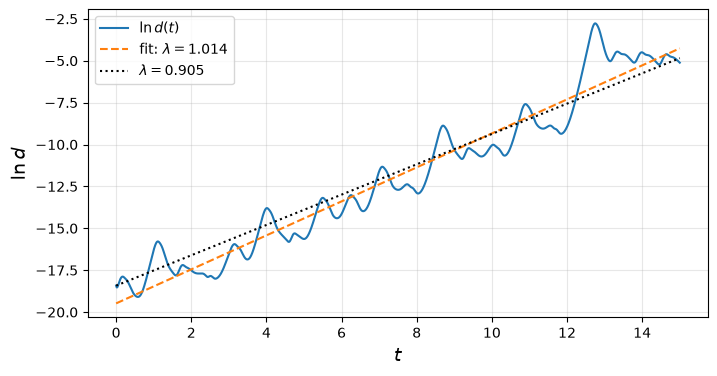

In [6]:
t, d = razdalja(u_a, t_fit[1])
k, n0 = np.polyfit(t, np.log(d), 1)
print(f"en par:        lambda_max = {k:.3f}")

# povprecje cez vec zacetnih tock na atraktorju
rng = np.random.default_rng(1)
naklon = []
u_i = u_a.copy()
for i in range(n_parov):
    u_i = solve_ivp(lorenz, (0, rng.uniform(5, 15)), u_i, rtol=rtol, atol=atol).y[:, -1]
    t_i, d_i = razdalja(u_i, t_fit[1])
    naklon.append(np.polyfit(t_i, np.log(d_i), 1)[0])
print(f"{n_parov} parov:      lambda_max = {np.mean(naklon):.3f} +- {np.std(naklon) / np.sqrt(n_parov):.3f}")
print(f"QR (Benettin): lambda_max = {lam[0]:.3f}   (literatura 0.905)")

fig = plt.figure(figsize=(8, 4))
ax = fig.add_subplot(111)
ax.plot(t, np.log(d), label=r"$\ln d(t)$")
ax.plot(t, n0 + k * t, "--", label=rf"fit: $\lambda = {k:.3f}$")
ax.plot(t, np.log(d0) + 0.905 * t, ":", color="black", label=r"$\lambda = 0.905$")
ax.set_xlabel("$t$", fontsize=14)
ax.set_ylabel(r"$\ln d$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Naloga 2

Ueda (0.05, 7.5):  1799 razlicnih tock
(0.2, 0.3):        1 razlicnih tock -> periodicno


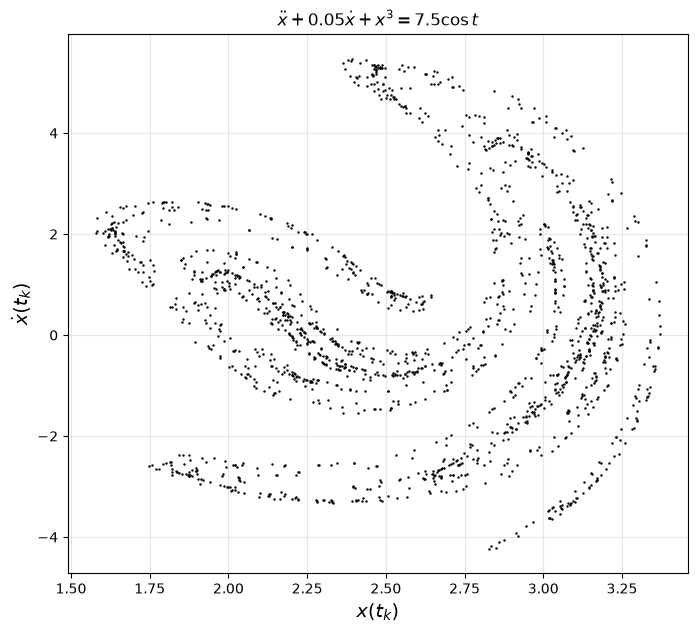

In [7]:
P = poincare(delta_d, F_d)
P_star = poincare(0.2, 0.3)     # parametri iz prve razlicice delovnega lista
print(f"Ueda (0.05, 7.5):  {len(np.unique(np.round(P.T, 4), axis=0))} razlicnih tock")
print(f"(0.2, 0.3):        {len(np.unique(np.round(P_star.T, 4), axis=0))} razlicnih tock -> periodicno")

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111)
ax.plot(P[0], P[1], ".", markersize=1.5, color="black")
ax.set_xlabel("$x(t_k)$", fontsize=14)
ax.set_ylabel(r"$\dot{x}(t_k)$", fontsize=14)
ax.set_title(r"$\ddot{x} + 0.05\dot{x} + x^3 = 7.5\cos t$")
ax.grid(alpha=0.3)
plt.show()

# Razmislek 1

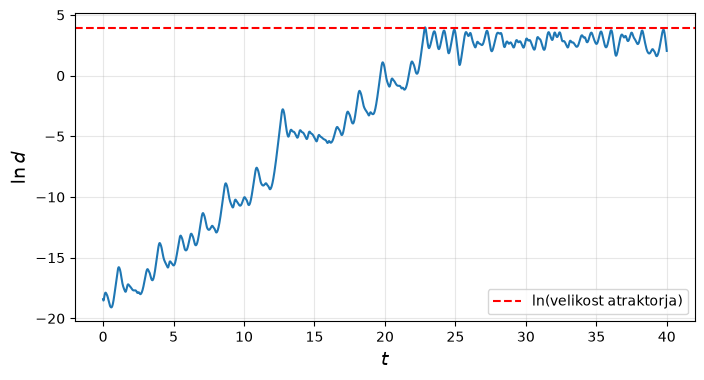

In [8]:
t, d = razdalja(u_a, 40.0, n=4001)
fig = plt.figure(figsize=(8, 4))
ax = fig.add_subplot(111)
ax.plot(t, np.log(d))
ax.axhline(np.log(np.ptp(sol.y, axis=1).max()), color="red", linestyle="--", label="ln(velikost atraktorja)")
ax.set_xlabel("$t$", fontsize=14)
ax.set_ylabel(r"$\ln d$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Razmislek 2

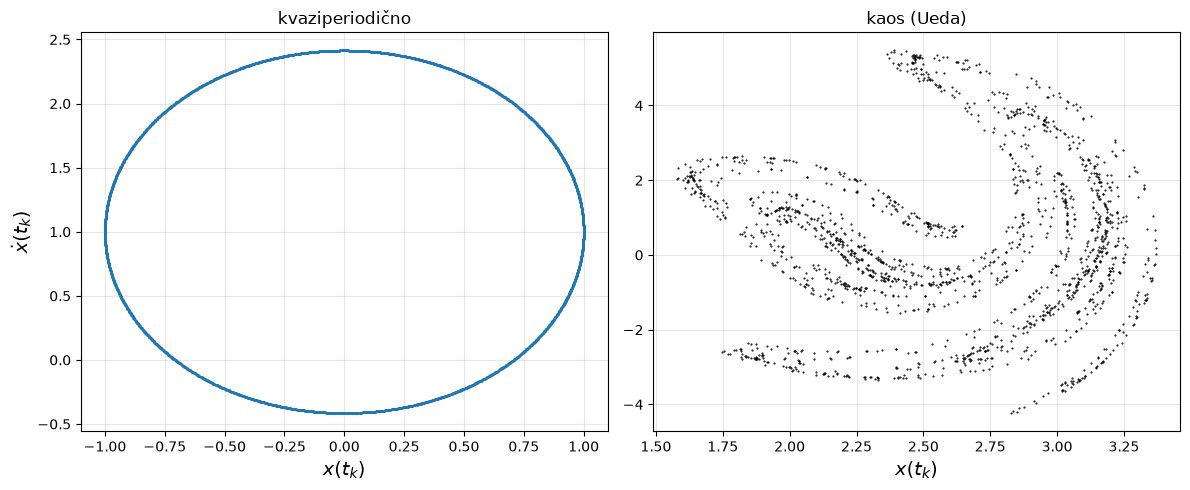

In [9]:
# Kvaziperiodicno: x(t) = sin t + sin(sqrt(2) t), presek ob t_k = 2 pi k -> sklenjena krivulja
tk = 2 * np.pi * np.arange(N_cikl)
xq = np.sin(tk) + np.sin(np.sqrt(2) * tk)
vq = np.cos(tk) + np.sqrt(2) * np.cos(np.sqrt(2) * tk)

fig = plt.figure(figsize=(12, 5))
ax = fig.add_subplot(121)
ax.plot(xq, vq, ".", markersize=2)
ax.set_title("kvaziperiodično")
ax.set_xlabel("$x(t_k)$", fontsize=14)
ax.set_ylabel(r"$\dot{x}(t_k)$", fontsize=14)
ax.grid(alpha=0.3)
ax = fig.add_subplot(122)
ax.plot(P[0], P[1], ".", markersize=1, color="black")
ax.set_title("kaos (Ueda)")
ax.set_xlabel("$x(t_k)$", fontsize=14)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()